# Gradients through a shock

In this tutorial, we follow a sine wave as it steepens into a standing shock under the viscous Burgers equation, a standard model of shock formation. We then differentiate a misfit at the final time through the solve with respect to the model's inputs. The problem is the standing-shock test of [Basdevant et al. (1986)](https://doi.org/10.1016/0045-7930(86)90036-8) at a larger viscosity, with the exact solution of [Cole (1951)](https://doi.org/10.1090/qam/42889). The inputs are first the viscosity and then the whole initial condition, and as their number grows we compare the cost of forward- and reverse-mode autodiff ([sensitivities](../overview/simulation/sensitivities.md)).

## Setup

We import diff-soup in JAX float64 (double-precision) mode. The grid and the parameter counts of the timing table depend on the device.

In [1]:
import textwrap
import time

import diff_soup as ds
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from diff_soup.domains import cartesian_grid_1d
from scipy.special import ive

jax.config.update("jax_enable_x64", True)
GPU = jax.default_backend() == "gpu"
N = 512 if GPU else 128                      # grid nodes
P = (1, 4, 16, 64, 256, N - 2) if GPU else (1, 4, 16, 64, N - 2)  # parameter counts to time
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0]}")

diff-soup 1.1.0, JAX 0.11.2, cuda:0


## The problem

We consider a velocity $u(x, t)$ that obeys the viscous Burgers equation,

$$
\frac{\partial u}{\partial t} + \frac{\partial}{\partial x}\Big(\frac{u^2}{2}\Big) = \nu\,\frac{\partial^2 u}{\partial x^2}, \qquad -1 < x < 1,
$$

where $\nu = 0.02$ is the viscosity, with $u(\pm 1, t) = 0$ and $u(x, 0) = -\sin(\pi x)$. The two halves of the wave run into each other at $x = 0$ and form a shock, a steep front of width about $2\nu/|u|$, which then decays.

The Cole-Hopf substitution $u = -2\nu\,\partial_x \log\varphi$ turns the equation into the heat equation for $\varphi$, so the exact solution is a ratio of two Fourier series, which `cole_hopf` evaluates.

In [2]:
def cole_hopf(x, t, nu, K=400):
    """Exact solution for u(x, 0) = -sin(pi x) on (-1, 1), as a ratio of two series."""
    k = np.arange(1, K + 1)[:, None]
    a = ive(k, 1 / (2 * np.pi * nu)) * (-1.0) ** k * np.exp(-nu * (k * np.pi) ** 2 * t)
    num = 4 * np.pi * nu * np.sum(k * a * np.sin(k * np.pi * x), axis=0)
    den = ive(0, 1 / (2 * np.pi * nu)) + 2 * np.sum(a * np.cos(k * np.pi * x), axis=0)
    return num / den

## Build the model

We declare the viscosity as a learnable parameter, so that a solve can take another value of it through `theta=`. Half cells at both ends of the grid put the first and last nodes on the boundary, where the Dirichlet condition holds.

In [3]:
grid = cartesian_grid_1d(N, -1.0, 1.0, half_cell_left=True, half_cell_right=True)
x = np.asarray(grid.nodes).ravel()
dx = x[1] - x[0]

spec = ds.problem("burgers")
spec.domain("line", grid)
spec.field("u", mass="differential", scale=1.0, init=lambda x: -jnp.sin(jnp.pi * x))
nu = spec.param("nu", value=0.02, learnable=True)

@spec.equation(writes="u", reads=("u",))
def burgers(q):
    return -q.ops.gradient(0.5 * q.u**2) + q.p.nu * q.ops.laplacian(q.u)

spec.bc.dirichlet("u", node_indices=np.array([0, N - 1]), value=0.0)
problem = spec.build()
y0 = spec.assemble_state({})

## Solve

We solve with `ds.JIDA` at tolerances of $10^{-8}$, tighter than the default, since the finite-difference checks later on are only as accurate as the solve.

diff_soup.RESULT<Solve reached t_end / converged.>


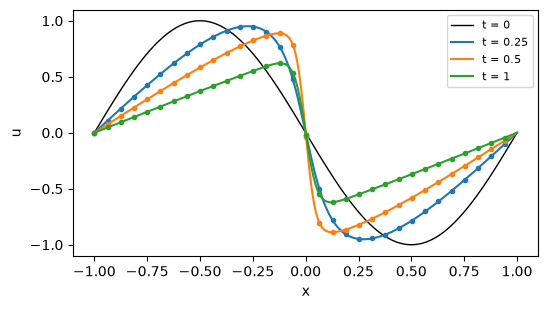

In [4]:
solver = ds.JIDA(rtol=1e-8, atol=1e-8)
T = 1.0
ts = np.array([0.25, 0.5, T])
sol = ds.pdesolve(problem, solver, (0.0, T), y0, saveat=ds.SaveAt(ts=ts))
print(sol.result)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(x, y0, "k", lw=1, label="t = 0")
for t, u in zip(ts, sol.ys):
    line, = ax.plot(x, u, lw=1.5, label=f"t = {t:g}")
    ax.plot(x[::N // 32], cole_hopf(x[::N // 32], t, 0.02), "o", ms=3, color=line.get_color())
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.legend(fontsize=8)
plt.show()

In the plot, the lines are the solve and the dots the exact solution, and the front at $x = 0$ is sharpest near $t = 0.5$.

## Check

At each save time, we print the largest pointwise error against the exact solution.

In [5]:
for t, u in zip(ts, sol.ys):
    print(f"t = {t:4.2f}   max |u - u_exact| = {np.abs(u - cole_hopf(x, t, 0.02)).max():.1e}")

t = 0.25   max |u - u_exact| = 1.7e-04
t = 0.50   max |u - u_exact| = 4.2e-04
t = 1.00   max |u - u_exact| = 1.3e-04


The error peaks at $4.2 \times 10^{-4}$ at $t = 0.5$, where the front is steepest and the grid resolves it worst. Even there, it is small next to the jump in $u$ across the shock.

## Differentiating the solve

We take as loss the squared misfit between the state at $t = T$ and the final state $u_{\text{ref}}$ of the solve at $\nu = 0.02$,

$$
\mathcal{L} = \tfrac{1}{2} \int_{-1}^{1} \big(u(x, T) - u_{\text{ref}}(x)\big)^2\,dx ,
$$

and start with its derivative with respect to a single parameter, the viscosity $\nu$.

In [6]:
u_ref = sol.ys[-1]

def loss_nu(nu_value, adjoint=None):
    theta = ds.default_theta(problem, {nu: nu_value})
    uT = ds.pdesolve(problem, solver, (0.0, T), y0, theta=theta, adjoint=adjoint).ys[-1]
    return 0.5 * dx * jnp.sum((uT - u_ref) ** 2)

def timed(f, *args):
    """Return f(*args), the first call's time (compile and run) and the second's (run)."""
    t0 = time.perf_counter(); jax.block_until_ready(f(*args))
    t1 = time.perf_counter(); out = jax.block_until_ready(f(*args))
    return out, t1 - t0, time.perf_counter() - t1

Inside the loss, `ds.default_theta(problem, {nu: value})` returns the parameter values for the solve with the viscosity replaced. The obvious first attempt at the gradient at $\nu = 0.03$ is `jax.grad`.

In [7]:
try:
    jax.grad(loss_nu)(0.03)
except ValueError as err:
    print(textwrap.fill(str(err), 90))

Reverse-mode differentiation (jax.grad, jax.vjp, jax.jacrev) was applied to a solve
running the forward-only adjoint, which is the default and supports jax.jvp and jax.jacfwd
only. For a reverse-mode gradient, solve with adjoint=ds.CheckpointAdjoint(). For reverse
mode over forward sensitivities, use adjoint=ds.ForwardAdjoint(composable=True).


The default adjoint runs forward mode only, and since forward mode pushes one tangent per input through the solve, `jax.jacfwd` suits a single parameter like this one. For reverse mode, we pass `adjoint=ds.CheckpointAdjoint()` to the solve, as the error suggests, and we check both against a central finite difference.

In [8]:
h = 1e-5
fd = (loss_nu(0.03 + h) - loss_nu(0.03 - h)) / (2 * h)
g_fwd, c_fwd, r_fwd = timed(jax.jit(jax.jacfwd(loss_nu)), 0.03)
g_rev, c_rev, r_rev = timed(jax.jit(jax.grad(lambda v: loss_nu(v, ds.CheckpointAdjoint()))), 0.03)
print(f"finite difference  dL/dnu = {fd:.8f}")
print(f"forward  (jacfwd)  dL/dnu = {g_fwd:.8f}   compile {c_fwd:5.1f} s, run {r_fwd * 1e3:6.1f} ms")
print(f"reverse  (grad)    dL/dnu = {g_rev:.8f}   compile {c_rev:5.1f} s, run {r_rev * 1e3:6.1f} ms")

finite difference  dL/dnu = 0.28426474
forward  (jacfwd)  dL/dnu = 0.28426476   compile   1.4 s, run   70.3 ms
reverse  (grad)    dL/dnu = 0.28426476   compile   4.4 s, run  193.4 ms


The two modes agree to every printed digit, and the finite difference agrees with them to about the solver tolerance. For one parameter, the forward-mode run takes 70 ms against 193 ms for reverse mode.

### The whole initial condition

Next, we take the $N$ nodal values of $u(x, 0)$ as the parameters, for which reverse mode returns all $N$ derivatives from one backward pass. We evaluate the gradient at a guess of 0.8 times the true initial condition and check it along a random direction against a central finite difference.

In [9]:
def loss_y0(y, adjoint=None):
    uT = ds.pdesolve(problem, solver, (0.0, T), y, adjoint=adjoint).ys[-1]
    return 0.5 * dx * jnp.sum((uT - u_ref) ** 2)

y_guess = 0.8 * y0
grad_y0 = jax.jit(jax.grad(lambda y: loss_y0(y, ds.CheckpointAdjoint())))
g, c, r = timed(grad_y0, y_guess)
print(f"reverse gradient, {g.size} entries: compile {c:.1f} s, run {r * 1e3:.1f} ms")

v = jax.random.normal(jax.random.PRNGKey(0), y0.shape)
fd = (loss_y0(y_guess + h * v) - loss_y0(y_guess - h * v)) / (2 * h)
print(f"directional derivative along a random v:  grad . v = {g @ v:.8f},  finite difference = {fd:.8f}")

reverse gradient, 512 entries: compile 4.3 s, run 244.8 ms


directional derivative along a random v:  grad . v = -0.00069638,  finite difference = -0.00069638


Along the random direction, the gradient matches the finite difference to every printed digit. Such a check covers one direction only, and checking every entry that way would take $2N$ solves. Next, we plot the final state that the guess produces, together with the gradient.

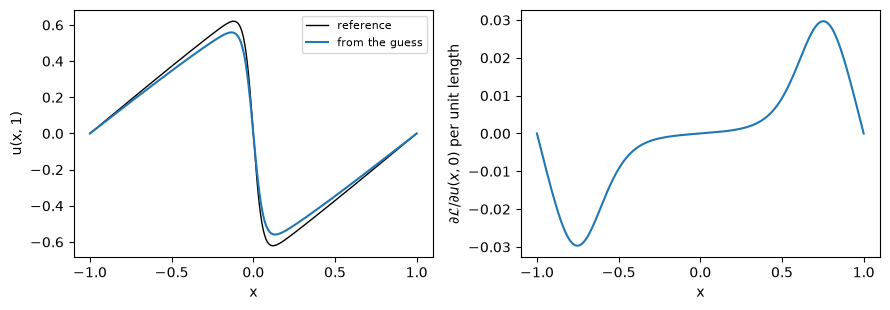

In [10]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)
uT_guess = ds.pdesolve(problem, solver, (0.0, T), y_guess).ys[-1]
ax0.plot(x, u_ref, "k", lw=1, label="reference")
ax0.plot(x, uT_guess, lw=1.5, label="from the guess")
ax0.set_xlabel("x")
ax0.set_ylabel(f"u(x, {T:g})")
ax0.legend(fontsize=8)
ax1.plot(x, g / dx, lw=1.5)
ax1.set_xlabel("x")
ax1.set_ylabel(r"$\partial\mathcal{L} / \partial u(x, 0)$ per unit length")
fig.tight_layout()
plt.show()

The guess gives a weaker shock at $t = T$. The gradient is negative where $u(x, 0) > 0$ and positive where it is negative, so a descent step grows the guess back towards the true amplitude.

### Cost against the number of parameters

To see how the cost scales, we write the initial condition as $p$ sine modes, $u(x, 0) = -\sum_{k=1}^{p} c_k \sin(k\pi x)$, and time both modes for each $p$ in `P`. The times are per call after the jit compile, in units of one solve without derivatives.

In [11]:
t_solve = timed(jax.jit(loss_y0), y_guess)[2]
print(f"one solve: {t_solve * 1e3:.1f} ms")
print("    p   forward   reverse   (times one solve)")
for p in P:
    basis = -jnp.sin(jnp.pi * jnp.arange(1, p + 1)[None, :] * jnp.asarray(x)[:, None])
    c0 = jnp.zeros(p).at[0].set(0.8)
    fwd = jax.jit(jax.jacfwd(lambda c: loss_y0(basis @ c)))
    rev = jax.jit(jax.grad(lambda c: loss_y0(basis @ c, ds.CheckpointAdjoint())))
    t_fwd = np.median([timed(fwd, c0)[2] for _ in range(3)])
    t_rev = np.median([timed(rev, c0)[2] for _ in range(3)])
    print(f"{p:5d}   {t_fwd / t_solve:7.1f}   {t_rev / t_solve:7.1f}")

one solve: 48.2 ms
    p   forward   reverse   (times one solve)


    1       1.7       5.1


    4       1.8       5.1


   16       2.0       5.1


   64       2.1       5.1


  256       2.8       5.1


  510       4.1       5.1


Reverse mode costs about five solves whatever $p$ is. Forward mode carries $p$ tangents through every step, so its cost grows with $p$, here from 1.7 to 4.1 solves.

!!! tip
    On this GPU, forward mode stays cheaper than reverse mode up to $p = N - 2 = 510$, the largest count we time. The crossover depends on the hardware, so time both modes on yours.